# <span style="color:green"> Numerical Simulation Laboratory (NSL) </span>
## <span style="color:blue">  Numerical exercises 4</span>

In [1]:
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import math

# Exercise 04.3

## Result

This section presents the study of time-reversal symmetry in Molecular Dynamics using the Verlet integration algorithm. 

Because the Verlet ODE integrator is intrinsically time-symmetric, exact trajectories are expected to be reversible under ideal conditions. However, due to finite time-step discretisation and floating-point precision limitations, numerical errors accumulate over time.


#### Simulation Setups

To test time reversal, the two last configurations of the forward run were used to restart the dynamics with their roles exchanged: the current configuration of the backward run is the second-to-last forward configuration $\vec r(T-\delta t)$, and the previous one is the final forward configuration $\vec r(T)$. Since the Verlet algorithm is time-symmetric, this is equivalent to inverting all the final velocities.

Two simulations were performed, both starting from the low-entropy FCC configuration:

* **Simulation 1:** 30 blocks $\times$ 180 steps ($5,400$ total steps) -> _conf1_
* **Simulation 2:** 100 blocks $\times$ 500 steps ($50,000$ total steps) -> _conf2_


#### Observations

1. **Short-Time Dynamics (Simulation 1):** 
     For these runs, the backward evolution successfully backtracks the forward path, yielding identical block-averaged thermodynamic properties in both temporal directions.

2. **Long-Time Dynamics (Simulation 2):** 
   When extending the evolution to $50,000$ total steps, the backward trajectory fails to return to the initial low-entropy FCC configuration.

While the Verlet integrator is formally time-reversible, the combination of a finite time step $\Delta t$ and floating-point round-off errors introduces tiny numerical perturbations at every integration step. Consequently, across long temporal scales, the numerical backward trajectory diverges from the original forward path (*Lyapunov instability*), illustrating the practical transition from microscopic reversibility to macroscopic irreversibility.

Last cell : *Simulation Visualization: Direct vs. Inverse Comparison*

---

**Exercise**


Starting from the **final states** of two MD simulations of the system in Exercise 04.2, one with about $5\times 10^3$ time-steps the other with about $5\times 10^4$ time-steps, by changing the direction of time (e.g. by inverting the final velocities, i.e. ... ), try to return back to the very low entropic initial configuration of Exercise 04.2. Is this possible? (for example, one can monitor the behavior of the average **potential energy** and the average **temperature** in **each block** as a function of time going **in both directions**. Show some picture and comment on what you find in your jupyter-notebook.


# First  Simulation 

---

## Direct Process
**Transition:** Low Entropy $\to$ High Entropy  
*(Evolution from the ordered FCC crystal lattice towards thermal equilibrium)*

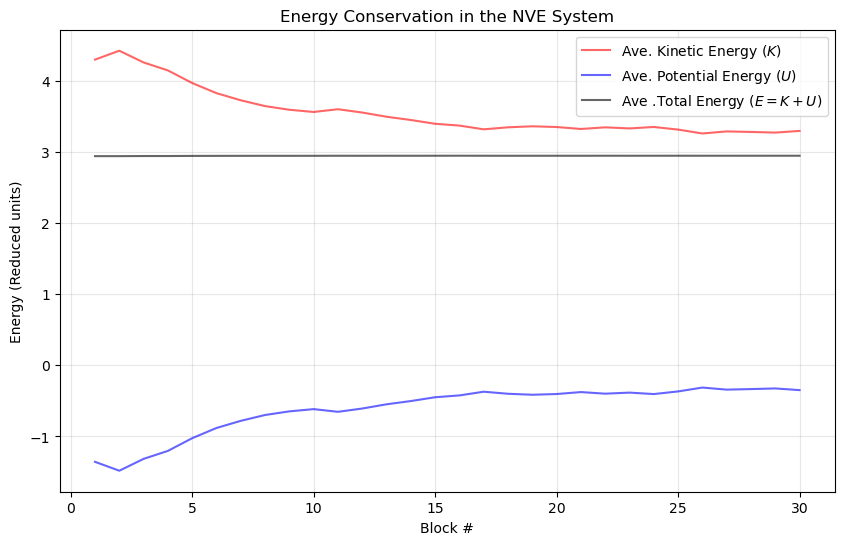

In [3]:


# Carico i dati
data1 = np.loadtxt("1/kinetic_energy.dat")
data2 = np.loadtxt("1/potential_energy.dat")
data3 = np.loadtxt("1/total_energy.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data1[:, 0]
ke = data1[:, 1]
pe = data2[:, 1]
tot=data3[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label='Ave. Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label='Ave. Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, tot, label='Ave .Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

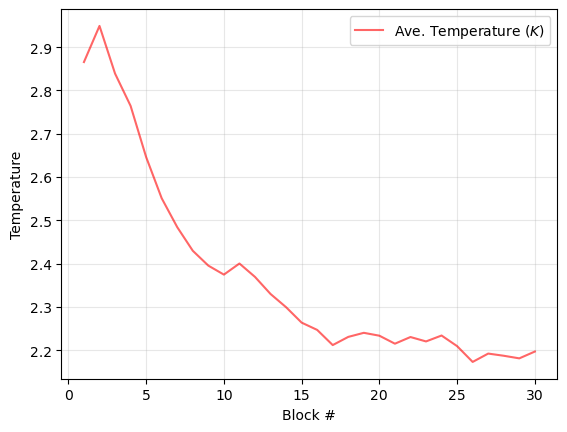

In [5]:
# Carico i dati
data4 = np.loadtxt("1/temperature.dat")
te = data4[:,1]
blocks_te = data4[:, 0]

# Plot delle componenti
plt.plot(blocks_te, te, label='Ave. Temperature ($K$)', color='red', alpha=0.6)

plt.title("")
plt.xlabel("Block #")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


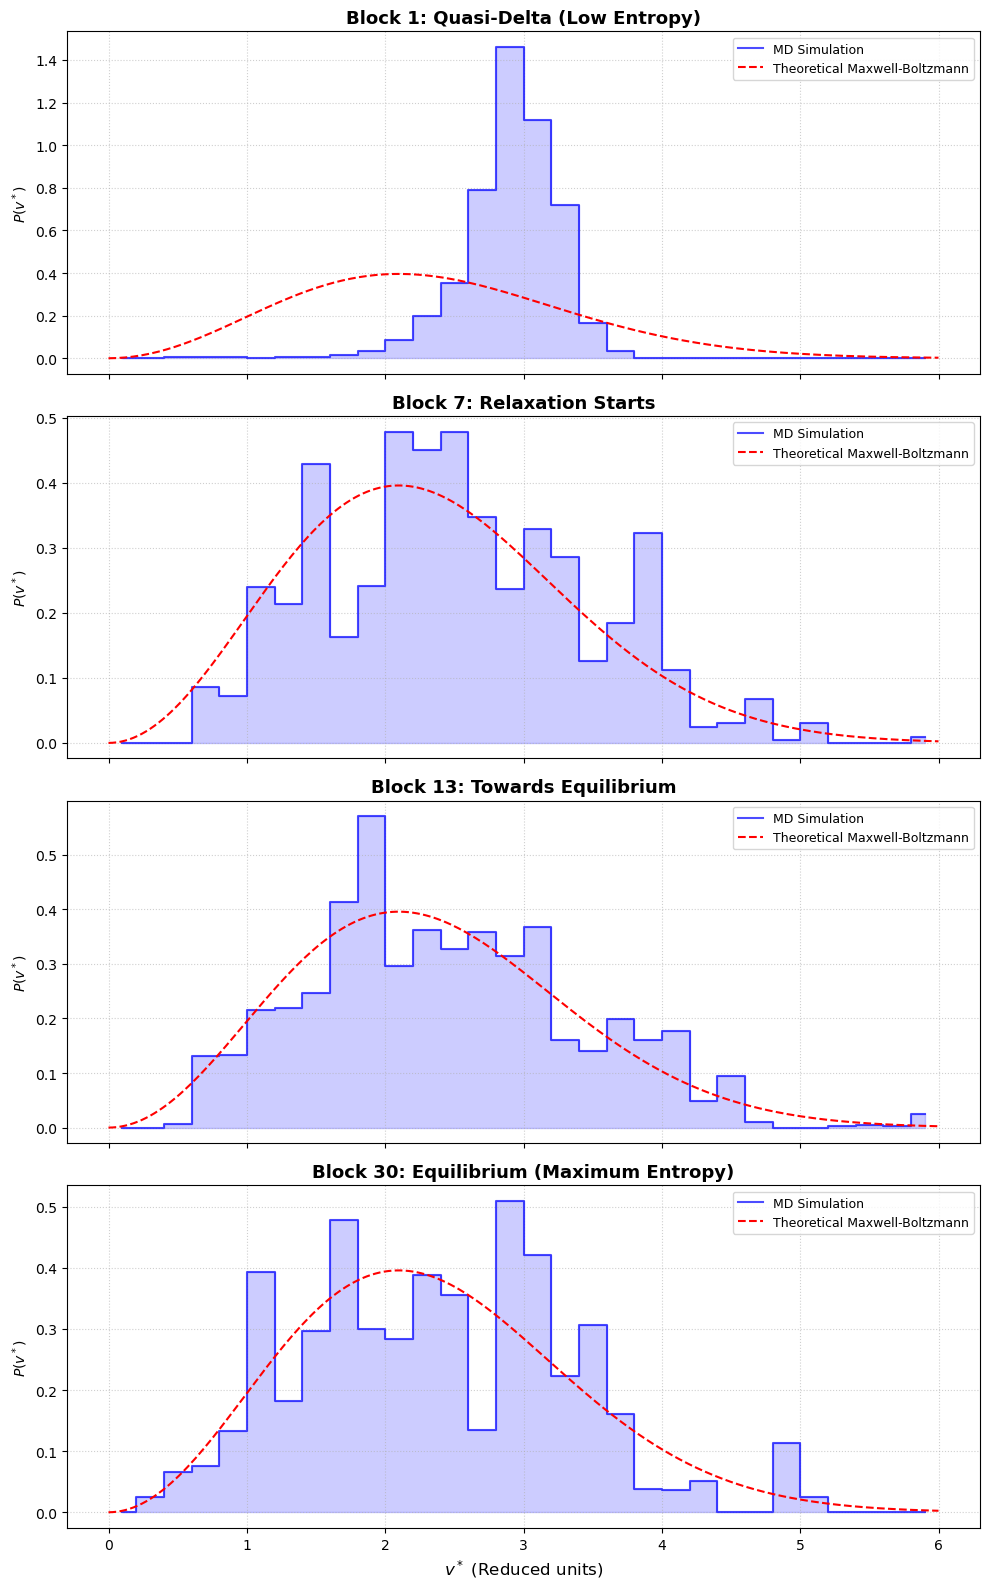

In [7]:
def plot_separated_histograms(filename):
    # Leggiamo il file e separiamo i blocchi
    with open(filename, 'r') as f:
        blocks = [b for b in f.read().split('\n\n\n') if b.strip()]


    indices = [0, 6, 12, len(blocks)-1]
    titles = [
        'Block 1: Quasi-Delta (Low Entropy)', 
        'Block 7: Relaxation Starts', 
        'Block 13: Towards Equilibrium', 
        'Block 30: Equilibrium (Maximum Entropy)'
    ]
    # Creiamo una figura con 4 grafici sovrapposti
    fig, axes = plt.subplots(4, 1, figsize=(10, 16), sharex=True)
    
    # Valore di Temperatura Effettiva (controlla il tuo temperature.dat!)
    T_eff = 2.2 
    v_range = np.linspace(0, 6, 200)
    maxwell = np.sqrt(2/np.pi) * (v_range**2 / (T_eff**1.5)) * np.exp(-(v_range**2)/(2*T_eff))

    for i, idx in enumerate(indices):
        data = np.genfromtxt(blocks[idx].splitlines())
        
        if data.size > 0:
            ax = axes[i]
            # Istogramma simulato
            ax.step(data[:, 0], data[:, 1], where='mid', color='blue', label='MD Simulation', alpha=0.7)
            ax.fill_between(data[:, 0], data[:, 1], step="mid", alpha=0.2, color='blue')
            
            # Curva teorica di confronto
            ax.plot(v_range, maxwell, 'r--', lw=1.5, label='Theoretical Maxwell-Boltzmann')
            
            ax.set_title(titles[i], fontsize=13, fontweight='bold')
            ax.set_ylabel("$P(v^*)$")
            ax.legend(loc='upper right', fontsize=9)
            ax.grid(True, linestyle=':', alpha=0.6)

    plt.xlabel("$v^*$ (Reduced units)", fontsize=12)
    plt.tight_layout()
    plt.show()

# Esegui il plot
plot_separated_histograms('1/pofv_evolution.dat')    

## Inverse Process (Time Reversal)
**Transition:** High Entropy $\to$ Low Entropy  
*(Evolution backwards in time, attempting to reconstruct the initial ordered state)*

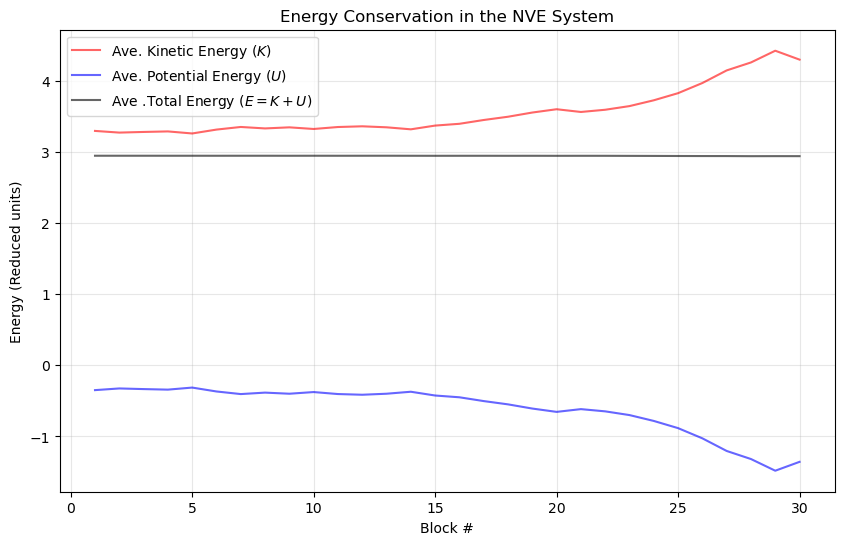

In [9]:
# Carico i dati
data5 = np.loadtxt("1/kinetic_energy2.dat")
data6 = np.loadtxt("1/potential_energy2.dat")
data7 = np.loadtxt("1/total_energy2.dat")

# Definisco le x (blocchi) e le y (energie)
blocks = data5[:, 0]
ke = data5[:, 1]
pe = data6[:, 1]
tot=data7[:,1]

plt.figure(figsize=(10,6))

# Plot delle componenti
plt.plot(blocks, ke, label='Ave. Kinetic Energy ($K$)', color='red', alpha=0.6)
plt.plot(blocks, pe, label='Ave. Potential Energy ($U$)', color='blue', alpha=0.6)
plt.plot(blocks, tot, label='Ave .Total Energy ($E=K+U$)', color='black', alpha=0.6)

# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

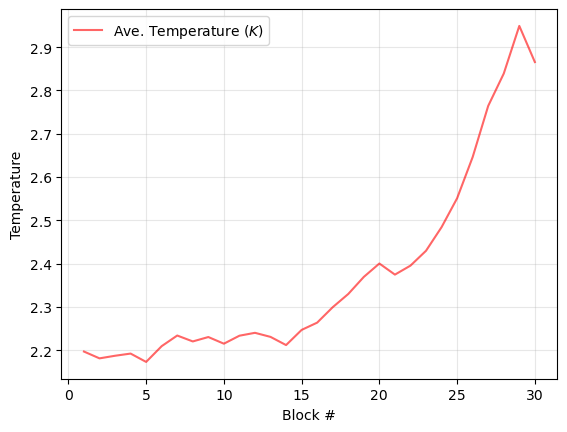

In [11]:
# Carico i dati
data8 = np.loadtxt("1/temperature2.dat")
te = data8[:,1]
blocks_te = data8[:, 0]

# Plot delle componenti
plt.plot(blocks_te, te, label='Ave. Temperature ($K$)', color='red', alpha=0.6)

plt.title("")
plt.xlabel("Block #")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()


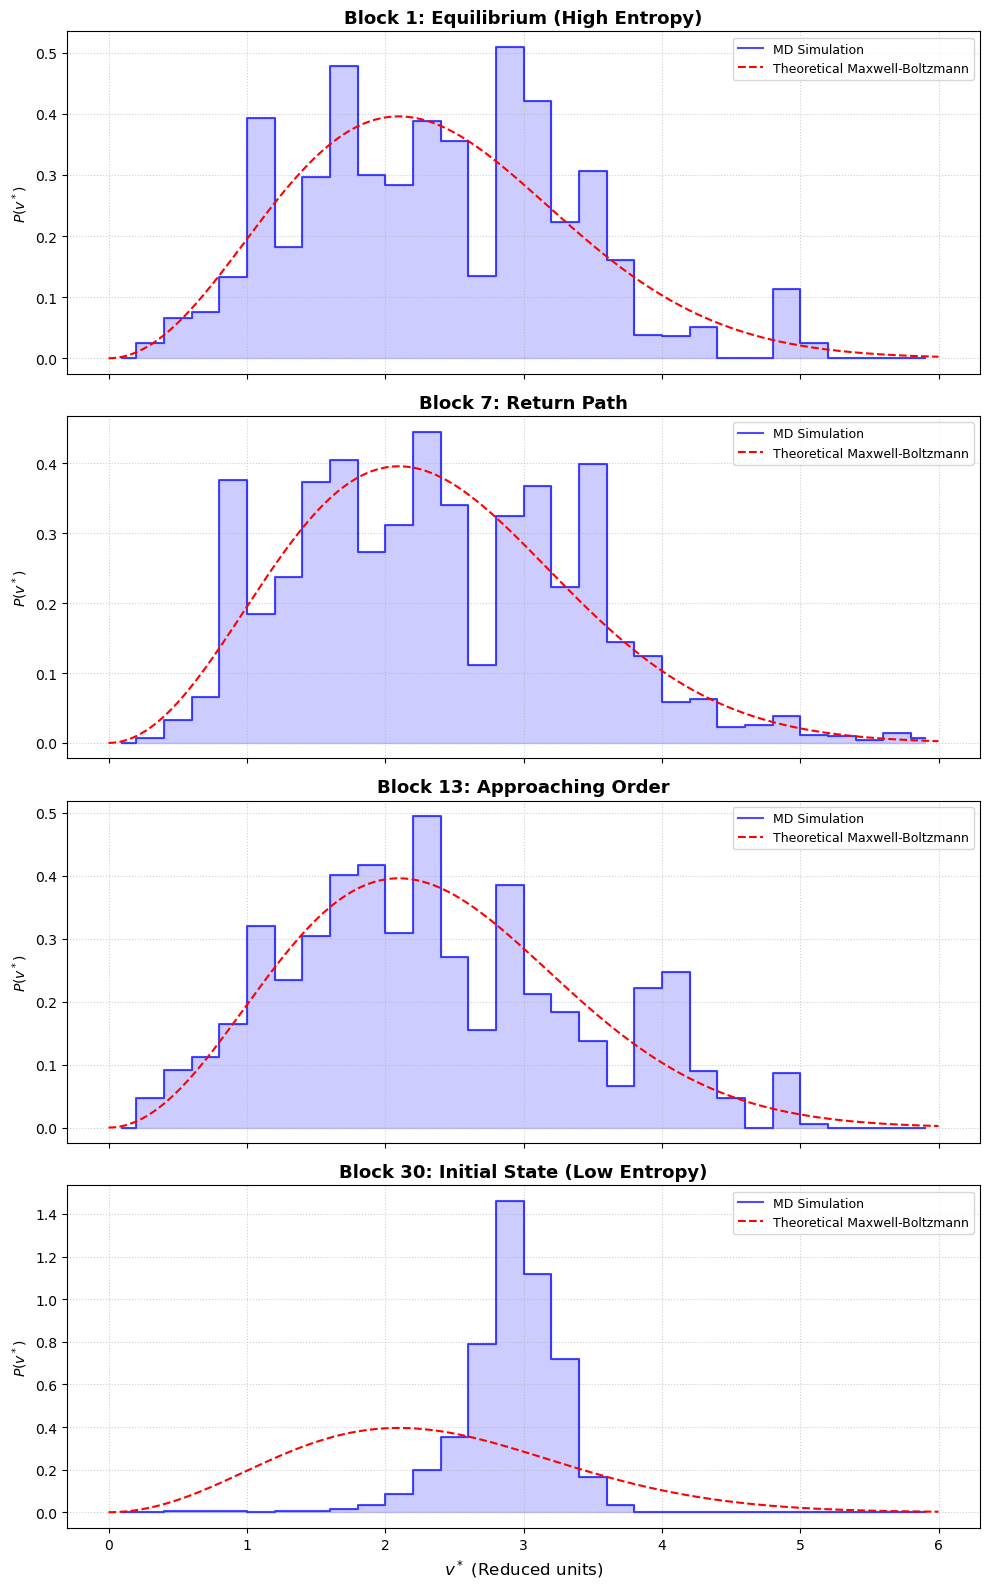

In [19]:
def plot_separated_histograms(filename):
    # Leggiamo il file e separiamo i blocchi
    with open(filename, 'r') as f:
        blocks = [b for b in f.read().split('\n\n\n') if b.strip()]


    indices = [0, 6, 12, len(blocks)-1]
    titles = [
        'Block 1: Equilibrium (High Entropy)',
        'Block 7: Return Path',
        'Block 13: Approaching Order',
        'Block 30: Initial State (Low Entropy)'
    ]

    # Creiamo una figura con 4 grafici sovrapposti
    fig, axes = plt.subplots(4, 1, figsize=(10, 16), sharex=True)
    
    # Valore di Temperatura Effettiva (controlla il tuo temperature.dat!)
    T_eff = 2.2 
    v_range = np.linspace(0, 6, 200)
    maxwell = np.sqrt(2/np.pi) * (v_range**2 / (T_eff**1.5)) * np.exp(-(v_range**2)/(2*T_eff))

    for i, idx in enumerate(indices):
        data = np.genfromtxt(blocks[idx].splitlines())
        
        if data.size > 0:
            ax = axes[i]
            # Istogramma simulato
            ax.step(data[:, 0], data[:, 1], where='mid', color='blue', label='MD Simulation', alpha=0.7)
            ax.fill_between(data[:, 0], data[:, 1], step="mid", alpha=0.2, color='blue')
            
            # Curva teorica di confronto
            ax.plot(v_range, maxwell, 'r--', lw=1.5, label='Theoretical Maxwell-Boltzmann')
            
            ax.set_title(titles[i], fontsize=13, fontweight='bold')
            ax.set_ylabel("$P(v^*)$")
            ax.legend(loc='upper right', fontsize=9)
            ax.grid(True, linestyle=':', alpha=0.6)

    plt.xlabel("$v^*$ (Reduced units)", fontsize=12)
    plt.tight_layout()
    plt.show()

# Esegui il plot
plot_separated_histograms('1/pofv_evolution2.dat')   

## Comparison: Direct vs. Inverse Process

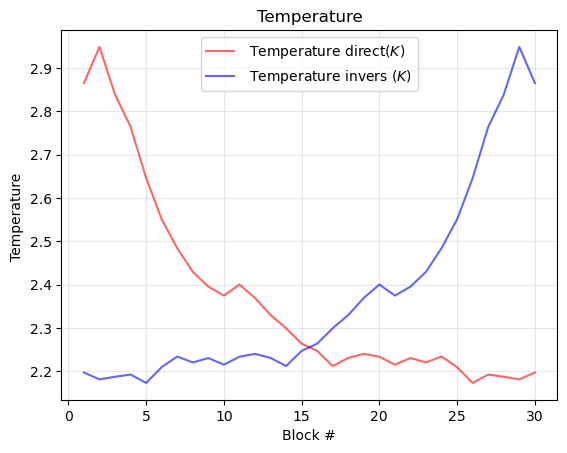

In [46]:
# Plot delle componenti
plt.plot(blocks, data4[:, 1]  , label=' Temperature direct($K$)', color='red', alpha=0.6)
plt.plot(blocks, data8[:, 1], label=' Temperature invers ($K$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Temperature")
plt.xlabel("Block #")
plt.ylabel("Temperature ")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

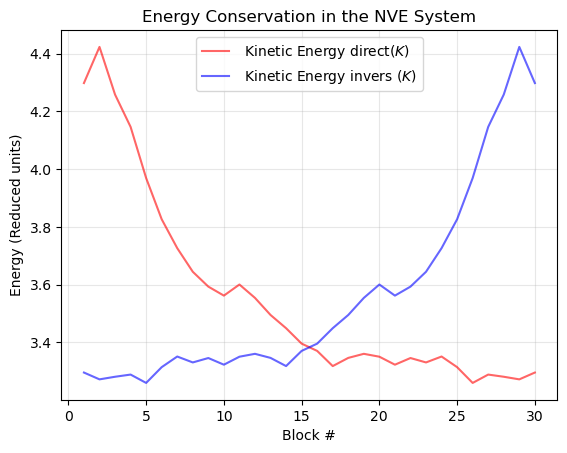

In [32]:
# Plot delle componenti
plt.plot(blocks, data1[:, 1]  , label=' Kinetic Energy direct($K$)', color='red', alpha=0.6)
plt.plot(blocks, data5[:, 1], label=' Kinetic Energy invers ($K$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)


plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

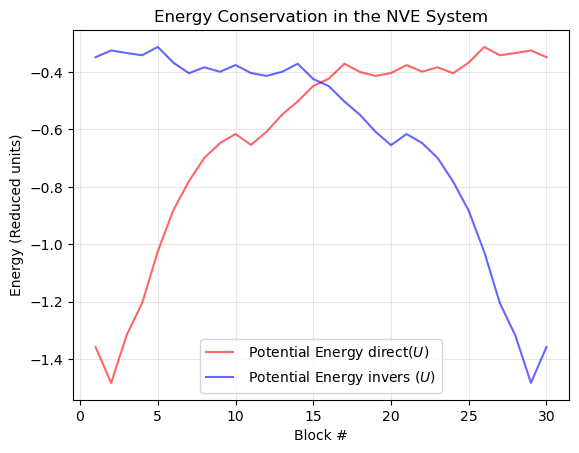

In [34]:
# Plot delle componenti
plt.plot(blocks, data2[:, 1]  , label=' Potential Energy direct($U$)', color='red', alpha=0.6)
plt.plot(blocks, data6[:, 1], label=' Potential Energy invers ($U$)', color='blue', alpha=0.6)


# Plot dell'Energia Totale (Somma delle componenti istantanee)

plt.title("Energy Conservation in the NVE System")
plt.xlabel("Block #")
plt.ylabel("Energy (Reduced units)")
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

## Simulation Visualization: Direct vs. Inverse Comparison

In [50]:
from IPython.display import HTML

# Sostituisci i nomi dei file con i tuoi
video1 = "simulazione_diretta.mp4"
video2 = "simulazione_inversa.mp4"

HTML(f'''
<div style="display: flex; justify-content: space-around;">
    <div style="flex: 1; padding: 5px;">
        <video width="100%" controls>
            <source src="{video1}" type="video/mp4">
        </video>
        <p style="text-align: center;">Direct simulation</p>
    </div>
    <div style="flex: 1; padding: 5px;">
        <video width="100%" controls>
            <source src="{video2}" type="video/mp4">
        </video>
        <p style="text-align: center;">Inverse simulation</p>
    </div>
</div>
''')